In [1]:
!pip install torchvision scikit-learn matplotlib seaborn pandas pillow tqdm

In [2]:
import os
import zipfile
import copy
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torchvision.datasets import ImageFolder
from torchvision.models import vgg16, VGG16_Weights

from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

from PIL import Image
from tqdm.notebook import tqdm

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():

    device = torch.device("cuda")

    print("GPU Name:", torch.cuda.get_device_name(0))

    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

else:
    device = torch.device("cpu")
    print("GPU not available. Using CPU.")

print("Selected Device:", device)

PyTorch Version: 2.5.1
Torchvision Version: 0.20.1
CUDA Available: True
GPU Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU Memory: 6.0 GB
Selected Device: cuda


In [4]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU Name:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
    print("Selected Device: GPU (" + str(device) + ")")
else:
    device = torch.device("cpu")
    print("GPU not available. Using CPU.")
    print("Selected Device: CPU")


GPU Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU Memory: 6.0 GB
Selected Device: GPU (cuda)


In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 2
LEARNING_RATE = 0.0001

NUM_WORKERS = 0

print("Configuration completed!")

Configuration completed!


In [6]:
import os
import tkinter as tk
from tkinter import filedialog

FILENAME = "MangoLeafBD Dataset.zip"
CURRENT_DIR_PATH = os.path.join(os.getcwd(), FILENAME)
BACKUP_PATH = r"E:\MY projects\MangoLeafBD Dataset.zip"

if os.path.exists(CURRENT_DIR_PATH):
  ZIP_PATH = CURRENT_DIR_PATH
elif os.path.exists(BACKUP_PATH):
  ZIP_PATH = BACKUP_PATH
else:
  root = tk.Tk()
  root.withdraw()
  ZIP_PATH = filedialog.askopenfilename(
      title="Select MangoLeafBD Dataset ZIP", filetypes=[("ZIP files", "*.zip")]
  )

if not ZIP_PATH:
  raise FileNotFoundError("Please select your dataset ZIP file.")

print("Selected Dataset:", ZIP_PATH)


Selected Dataset: E:\MY projects\MANGO LEAF DISEASE PREDICTION\MangoLeafBD Dataset.zip


In [7]:
EXTRACT_PATH = os.path.join(
    os.path.dirname(ZIP_PATH),
    "MangoLeafBD_Extracted"
)

os.makedirs(EXTRACT_PATH, exist_ok=True)

if not os.listdir(EXTRACT_PATH):

    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

    print("Dataset extracted successfully!")

else:
    print("Dataset already extracted. Skipping extraction.")

DATASET_PATH = os.path.join(
    EXTRACT_PATH,
    "MangoLeafBD Dataset"
)

print("Dataset Path:", DATASET_PATH)
print("Dataset Exists:", os.path.exists(DATASET_PATH))

Dataset already extracted. Skipping extraction.
Dataset Path: E:\MY projects\MANGO LEAF DISEASE PREDICTION\MangoLeafBD_Extracted\MangoLeafBD Dataset
Dataset Exists: True


In [8]:
classes = sorted([
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

print("Total Classes:", len(classes))

for cls in classes:

    folder_path = os.path.join(DATASET_PATH, cls)

    count = len([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    print(cls, ":", count, "images")

Total Classes: 8
Anthracnose : 500 images
Bacterial Canker : 500 images
Cutting Weevil : 500 images
Die Back : 500 images
Gall Midge : 500 images
Healthy : 500 images
Powdery Mildew : 500 images
Sooty Mould : 500 images


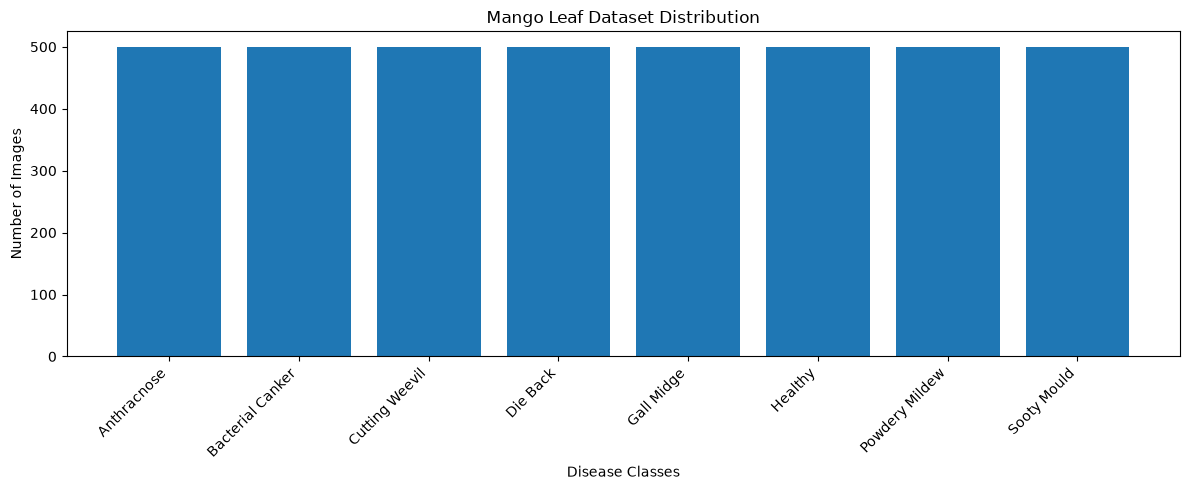

Anthracnose         500
Bacterial Canker    500
Cutting Weevil      500
Die Back            500
Gall Midge          500
Healthy             500
Powdery Mildew      500
Sooty Mould         500
dtype: int64


In [9]:
class_counts = {}

for cls in classes:

    folder_path = os.path.join(DATASET_PATH, cls)

    class_counts[cls] = len([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

plt.figure(figsize=(12, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Mango Leaf Dataset Distribution")
plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(pd.Series(class_counts))

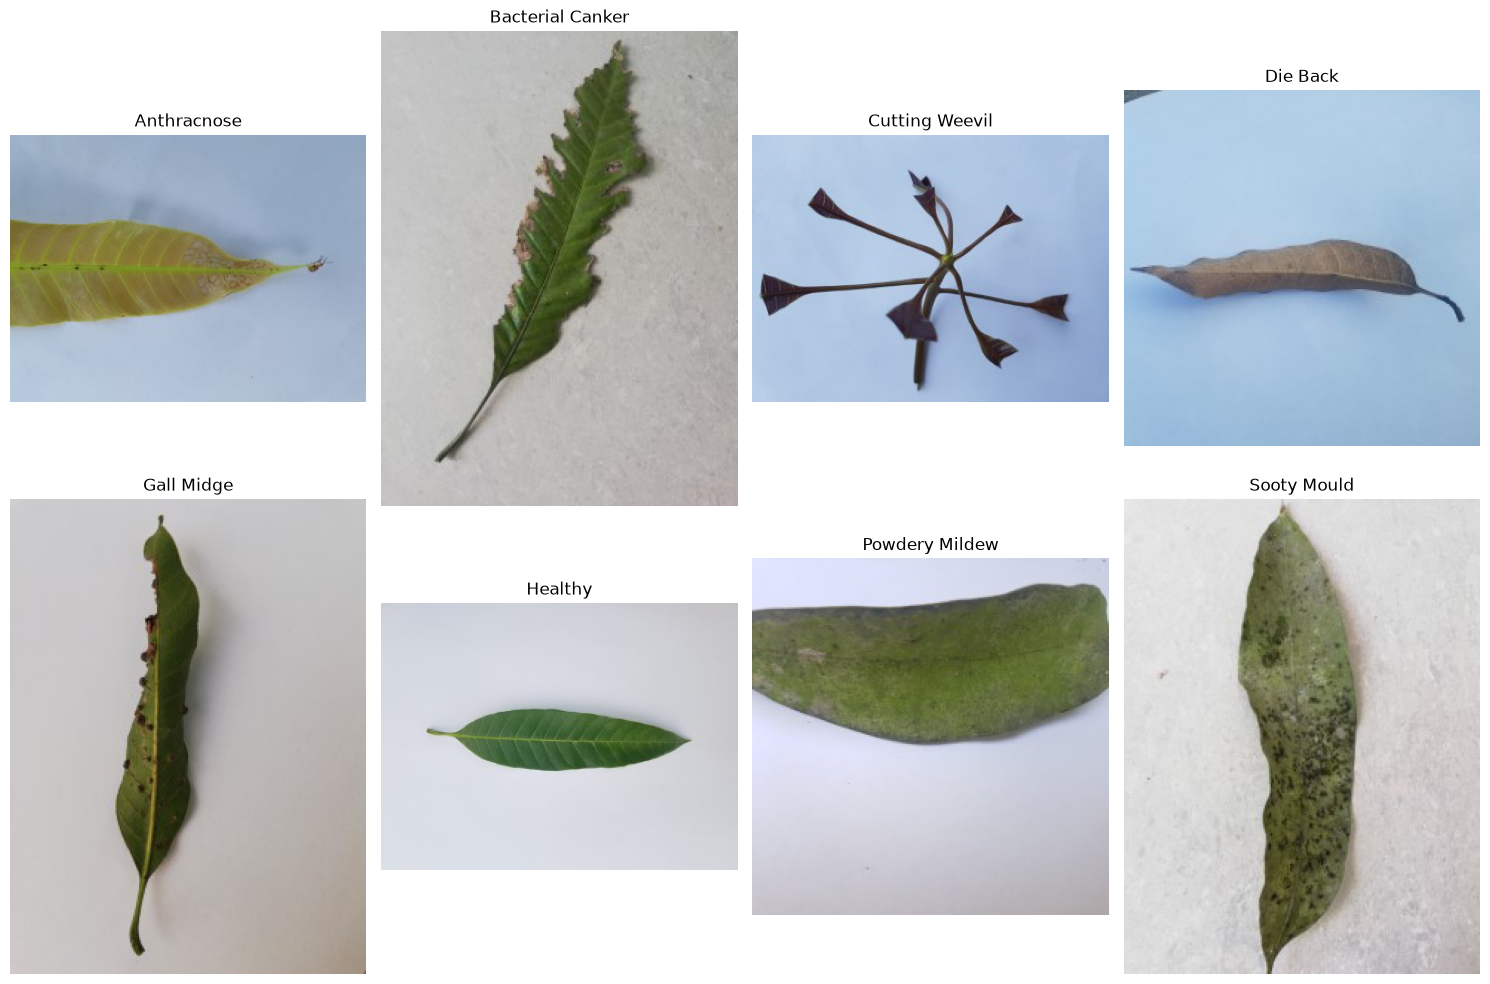

In [10]:
plt.figure(figsize=(15, 10))

for i, cls in enumerate(classes):

    folder_path = os.path.join(DATASET_PATH, cls)

    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    img_path = os.path.join(folder_path, images[0])

    img = Image.open(img_path).convert('RGB')

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [11]:
train_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing completed!")

Image preprocessing completed!


In [12]:
# Load datasets with identical image ordering
base_dataset = ImageFolder(DATASET_PATH)

train_dataset_full = ImageFolder(
    DATASET_PATH,
    transform=train_transform
)

eval_dataset_full = ImageFolder(
    DATASET_PATH,
    transform=test_transform
)

class_names = base_dataset.classes

class_to_idx = base_dataset.class_to_idx

targets = np.array(base_dataset.targets)

indices = np.arange(len(base_dataset))

# 70% training and 30% remaining
train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=targets
)

# Split remaining 30% into 15% validation and 15% testing
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=targets[temp_indices]
)

train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    eval_dataset_full,
    val_indices
)

test_dataset = Subset(
    eval_dataset_full,
    test_indices
)

print("Total Images:", len(base_dataset))
print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))

print("\nClasses:", class_names)

Total Images: 4000
Training Images: 2800
Validation Images: 600
Testing Images: 600

Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']


In [13]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("DataLoaders created successfully!")

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

DataLoaders created successfully!
Training Batches: 175
Validation Batches: 38
Testing Batches: 38


In [14]:
# Load pretrained VGG16
model = vgg16(
    weights=VGG16_Weights.IMAGENET1K_V1
)

# Freeze pretrained feature extraction layers
for param in model.features.parameters():
    param.requires_grad = False

# Replace original classifier
model.classifier = nn.Sequential(

    nn.Linear(512 * 7 * 7, 512),

    nn.ReLU(inplace=True),

    nn.Dropout(0.5),

    nn.Linear(512, len(class_names))
)

# Move model to GPU
model = model.to(device)

print("VGG16 Model Created Successfully!")
print("Number of Classes:", len(class_names))

print(model)

VGG16 Model Created Successfully!
Number of Classes: 8
VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): M

In [15]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=LEARNING_RATE
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.2,
    patience=2
)

print("Loss Function:", criterion)
print("Optimizer: Adam")
print("Learning Rate:", LEARNING_RATE)

Loss Function: CrossEntropyLoss()
Optimizer: Adam
Learning Rate: 0.0001


In [16]:
history = {
    'train_loss': [],
    'val_loss': [],
    'train_accuracy': [],
    'val_accuracy': []
}

best_val_loss = float('inf')
patience = 4
counter = 0

best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):

    # ---------------- TRAINING ----------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} Training"
    )

    for images, labels in train_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        train_bar.set_postfix(
            loss=loss.item()
        )

    train_loss = running_loss / total
    train_acc = correct / total

    # ---------------- VALIDATION ----------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)

            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    # Store history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)

    history['train_accuracy'].append(train_acc)
    history['val_accuracy'].append(val_acc)

    scheduler.step(val_loss)

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc*100:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc*100:.2f}%")

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_weights = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model_weights,
            "best_vgg16_mango.pth"
        )

        counter = 0

        print("Best model saved!")

    else:

        counter += 1

    if counter >= patience:

        print("Early stopping activated!")

        break

# Restore best weights
model.load_state_dict(best_model_weights)

print("\nVGG16 Training Completed!")

Epoch 1/2 Training:   0%|          | 0/175 [00:00<?, ?it/s]


Epoch [1/2]
Train Loss: 0.5495
Train Accuracy: 83.00%
Validation Loss: 0.1148
Validation Accuracy: 97.33%
Best model saved!


Epoch 2/2 Training:   0%|          | 0/175 [00:00<?, ?it/s]


Epoch [2/2]
Train Loss: 0.1236
Train Accuracy: 96.68%
Validation Loss: 0.0446
Validation Accuracy: 99.00%
Best model saved!

VGG16 Training Completed!


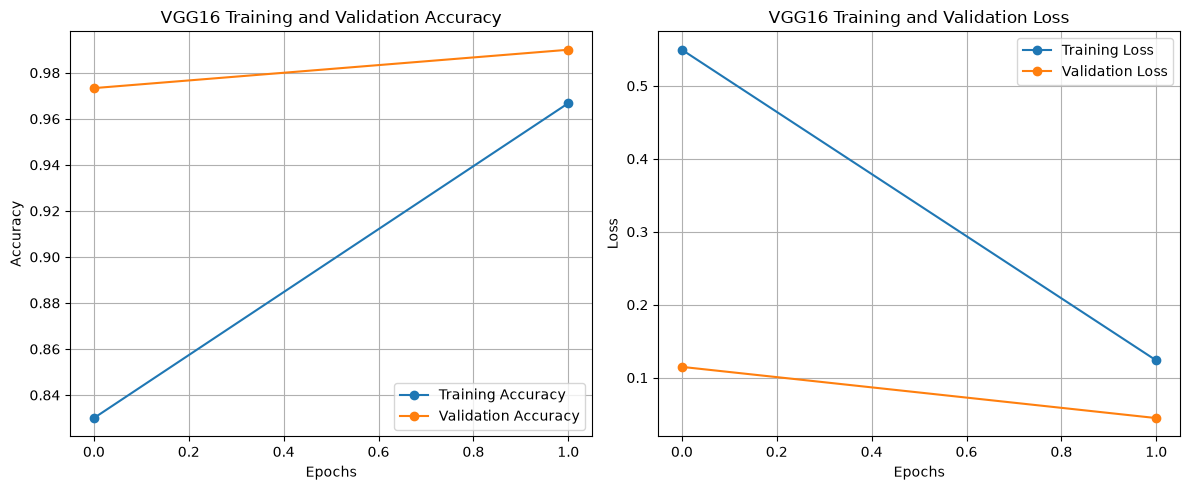

In [17]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history['train_accuracy'],
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    history['val_accuracy'],
    marker='o',
    label='Validation Accuracy'
)

plt.title("VGG16 Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)

plt.plot(
    history['train_loss'],
    marker='o',
    label='Training Loss'
)

plt.plot(
    history['val_loss'],
    marker='o',
    label='Validation Loss'
)

plt.title("VGG16 Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [18]:
model.eval()

all_predictions = []
all_labels = []

test_loss = 0.0
total = 0
correct = 0

with torch.no_grad():

    for images, labels in tqdm(test_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

        all_predictions.extend(
            predicted.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

test_loss = test_loss / total

test_accuracy = correct / total

print("VGG16 Test Loss:", round(test_loss, 4))

print(
    "VGG16 Test Accuracy: {:.2f}%".format(
        test_accuracy * 100
    )
)

  0%|          | 0/38 [00:00<?, ?it/s]

VGG16 Test Loss: 0.0579
VGG16 Test Accuracy: 98.83%


In [19]:
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average='weighted',
    zero_division=0
)

print("\n========== VGG16 PERFORMANCE ==========")

print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")


========== VGG16 PERFORMANCE ==========
Accuracy  : 98.83%
Precision : 98.85%
Recall    : 98.83%
F1 Score  : 98.83%


In [20]:
print("\nVGG16 CLASSIFICATION REPORT\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


VGG16 CLASSIFICATION REPORT

                  precision    recall  f1-score   support

     Anthracnose     0.9867    0.9867    0.9867        75
Bacterial Canker     1.0000    1.0000    1.0000        75
  Cutting Weevil     1.0000    1.0000    1.0000        75
        Die Back     1.0000    1.0000    1.0000        75
      Gall Midge     1.0000    1.0000    1.0000        75
         Healthy     0.9867    0.9867    0.9867        75
  Powdery Mildew     0.9487    0.9867    0.9673        75
     Sooty Mould     0.9861    0.9467    0.9660        75

        accuracy                         0.9883       600
       macro avg     0.9885    0.9883    0.9883       600
    weighted avg     0.9885    0.9883    0.9883       600



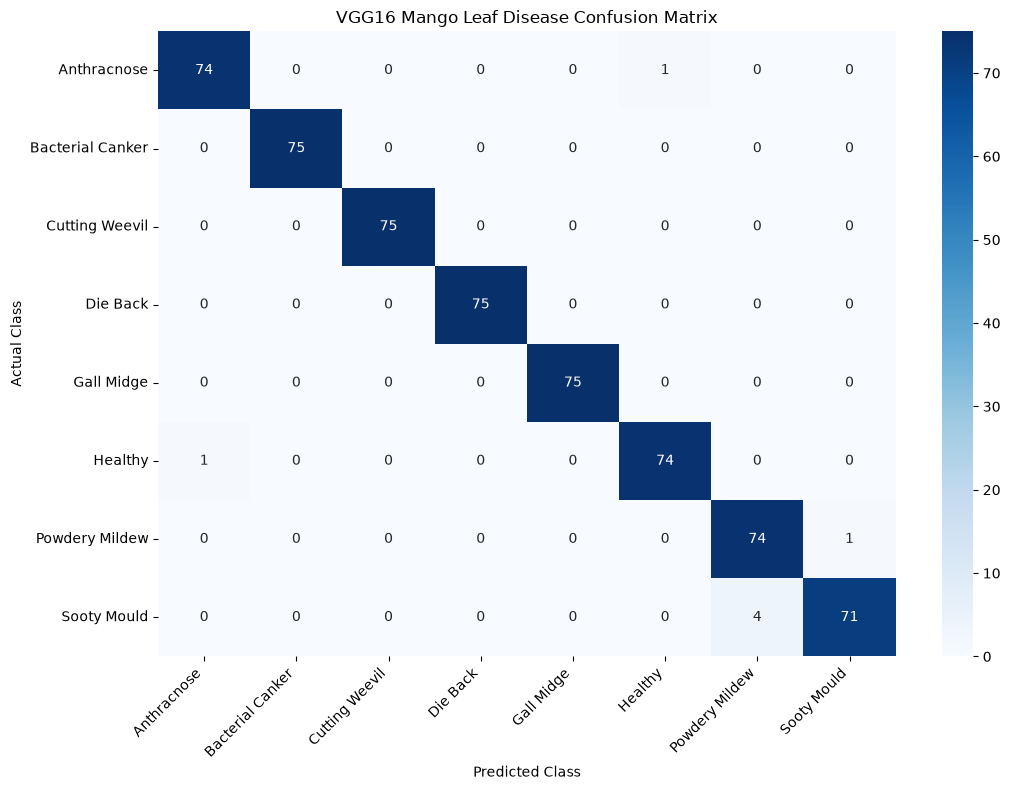

In [21]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("VGG16 Mango Leaf Disease Confusion Matrix")

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

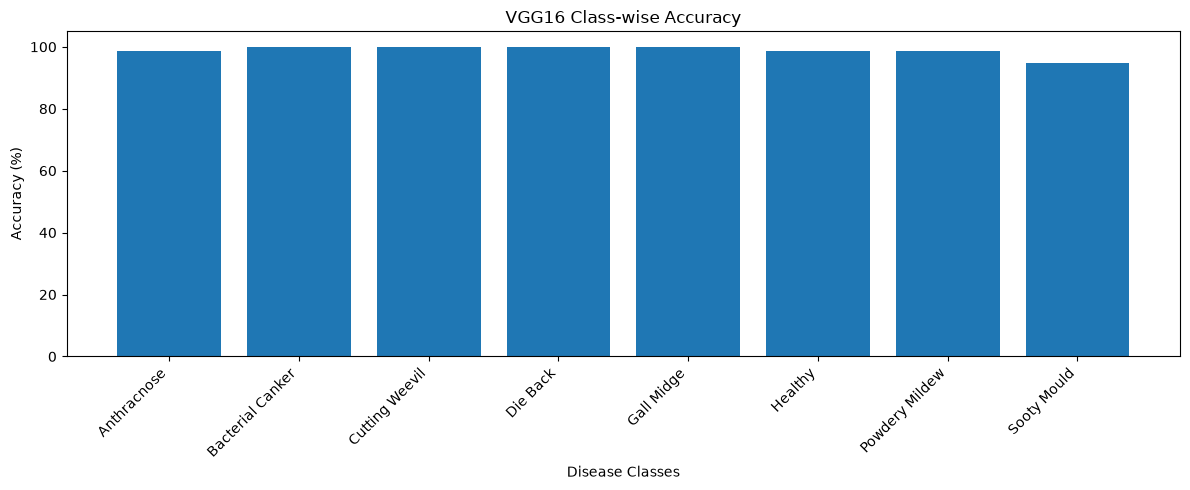

Anthracnose          98.666667
Bacterial Canker    100.000000
Cutting Weevil      100.000000
Die Back            100.000000
Gall Midge          100.000000
Healthy              98.666667
Powdery Mildew       98.666667
Sooty Mould          94.666667
dtype: float64


In [22]:
class_accuracy = {}

for i, cls in enumerate(class_names):

    indices = np.array(all_labels) == i

    correct_predictions = (
        np.array(all_predictions)[indices] == i
    ).sum()

    total_samples = indices.sum()

    class_accuracy[cls] = (
        correct_predictions / total_samples
    ) * 100

plt.figure(figsize=(12, 5))

plt.bar(
    class_accuracy.keys(),
    class_accuracy.values()
)

plt.title("VGG16 Class-wise Accuracy")
plt.xlabel("Disease Classes")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

print(pd.Series(class_accuracy))

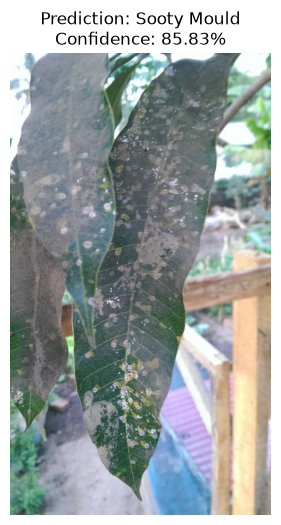

Predicted Disease: Sooty Mould
Confidence: 85.83%
Prediction Time: 0.155 seconds
Total Time: 0.634 seconds
Device: cuda


In [30]:
import time
from tkinter import Tk, filedialog

# Select image
root = Tk()
root.withdraw()
root.attributes('-topmost', True)

image_path = filedialog.askopenfilename(
    title="Select Mango Leaf Image",
    filetypes=[("Images", "*.jpg *.jpeg *.png")]
)

root.destroy()

if not image_path:
    raise ValueError("No image selected!")

start_time = time.time()

# Load image
img = Image.open(image_path).convert('RGB')

# Preprocessing
input_tensor = test_transform(img).unsqueeze(0).to(device)

# Prediction
model.eval()

if device.type == 'cuda':
    torch.cuda.synchronize()

prediction_start = time.time()

with torch.inference_mode():
    output = model(input_tensor)
    probabilities = torch.softmax(output, dim=1)

if device.type == 'cuda':
    torch.cuda.synchronize()

prediction_time = time.time() - prediction_start

confidence, predicted_index = torch.max(
    probabilities, dim=1
)

predicted_class = class_names[predicted_index.item()]
confidence_score = confidence.item() * 100

# Display result
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title(
    f"Prediction: {predicted_class}\nConfidence: {confidence_score:.2f}%"
)
plt.axis('off')
plt.show()

print("Predicted Disease:", predicted_class)
print(f"Confidence: {confidence_score:.2f}%")
print(f"Prediction Time: {prediction_time:.3f} seconds")
print(f"Total Time: {time.time() - start_time:.3f} seconds")
print("Device:", device)

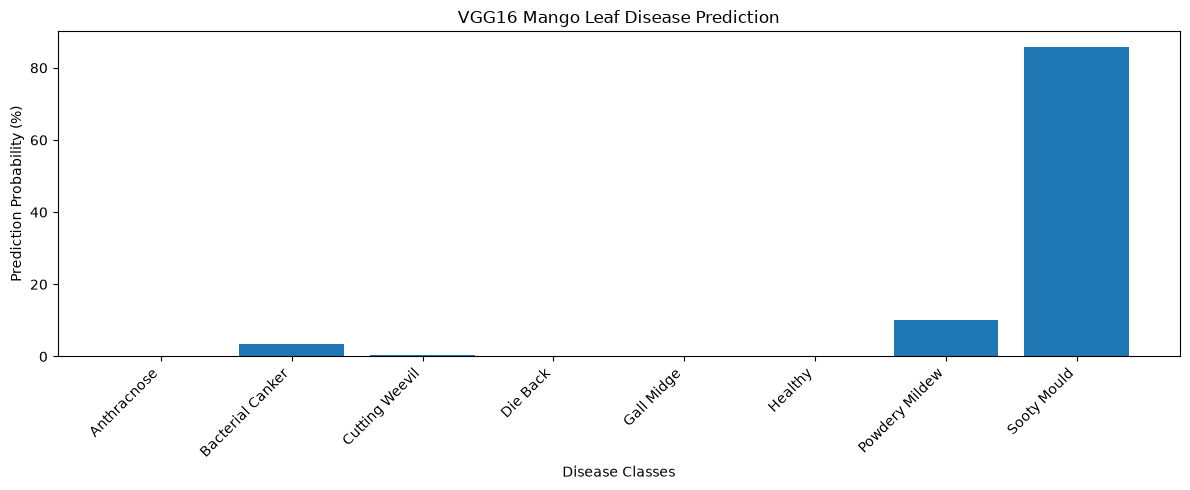

Anthracnose: 0.20%
Bacterial Canker: 3.42%
Cutting Weevil: 0.29%
Die Back: 0.07%
Gall Midge: 0.04%
Healthy: 0.05%
Powdery Mildew: 10.09%
Sooty Mould: 85.83%


In [31]:
probability_values = probabilities[0].cpu().numpy() * 100

plt.figure(figsize=(12, 5))

plt.bar(
    class_names,
    probability_values
)

plt.title("VGG16 Mango Leaf Disease Prediction")
plt.xlabel("Disease Classes")
plt.ylabel("Prediction Probability (%)")

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

for cls, prob in zip(class_names, probability_values):

    print(f"{cls}: {prob:.2f}%")

In [32]:
checkpoint = {
    'model_state_dict': model.state_dict(),
    'class_names': class_names,
    'class_to_idx': class_to_idx,
    'image_size': IMG_SIZE,
    'architecture': 'VGG16'
}

torch.save(
    checkpoint,
    'MangoLeaf_VGG16_PyTorch.pth'
)

print("VGG16 model checkpoint saved successfully!")

VGG16 model checkpoint saved successfully!


In [33]:
with open(
    'MangoLeaf_VGG16_Labels.json',
    'w'
) as f:

    json.dump(
        class_to_idx,
        f,
        indent=4
    )

print("Class labels saved successfully!")

Class labels saved successfully!


In [29]:
import shutil

output_folder = "MangoLeaf_VGG16_Results"

os.makedirs(output_folder, exist_ok=True)

shutil.copy(
    'MangoLeaf_VGG16_PyTorch.pth',
    output_folder
)

shutil.copy(
    'MangoLeaf_VGG16_Labels.json',
    output_folder
)

print("Saved files:")

for file in os.listdir(output_folder):
    print(file)

print("\nResults folder:", os.path.abspath(output_folder))

Saved files:
MangoLeaf_VGG16_Labels.json
MangoLeaf_VGG16_PyTorch.pth

Results folder: E:\MY projects\MANGO LEAF DISEASE PREDICTION\MangoLeaf_VGG16_Results


In [34]:

import os
import torch
import json

# Create folder to store the trained model
SAVE_DIR = "MangoLeaf_VGG16_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save complete model checkpoint
model_path = os.path.join(SAVE_DIR, "MangoLeaf_VGG16.pth")

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "class_to_idx": class_to_idx,
    "image_size": IMG_SIZE,
    "architecture": "VGG16",
    "num_classes": len(class_names)
}, model_path)

print("Model saved successfully!")
print("Model location:", os.path.abspath(model_path))

# Save class labels separately
labels_path = os.path.join(SAVE_DIR, "class_names.json")

with open(labels_path, "w") as f:
    json.dump(class_names, f, indent=4)

print("Class labels saved:", os.path.abspath(labels_path))


Model saved successfully!
Model location: E:\MY projects\MANGO LEAF DISEASE PREDICTION\MangoLeaf_VGG16_Models\MangoLeaf_VGG16.pth
Class labels saved: E:\MY projects\MANGO LEAF DISEASE PREDICTION\MangoLeaf_VGG16_Models\class_names.json


In [35]:

print("Saved model files:")

for file in os.listdir(SAVE_DIR):
    file_path = os.path.join(SAVE_DIR, file)
    print(file, " | Size:", round(os.path.getsize(file_path) / (1024 * 1024), 2), "MB")


Saved model files:
class_names.json  | Size: 0.0 MB
MangoLeaf_VGG16.pth  | Size: 105.16 MB
